In [1]:
# -----------------------
# Imports (shared)
# -----------------------
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib

# sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.compose import TransformedTargetRegressor





# statsmodels (used by regression notebook for p-values/outliers)
import statsmodels.api as sm

# boosting (used by weakest_link notebook)
from xgboost import XGBClassifier, XGBRegressor
from xgboost.callback import EarlyStopping
from lightgbm import LGBMClassifier, LGBMRegressor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


PART 1 — REGRESSION (AimoScore)
Dataset: 2094 samples, 43 columns
Features: 41
Target range: 0.01 - 0.99
Missing values in X: 0
Training: 1884 samples
Test:     210 samples
Baseline: R²=0.6226, RMSE=0.1585, MAE=0.1212


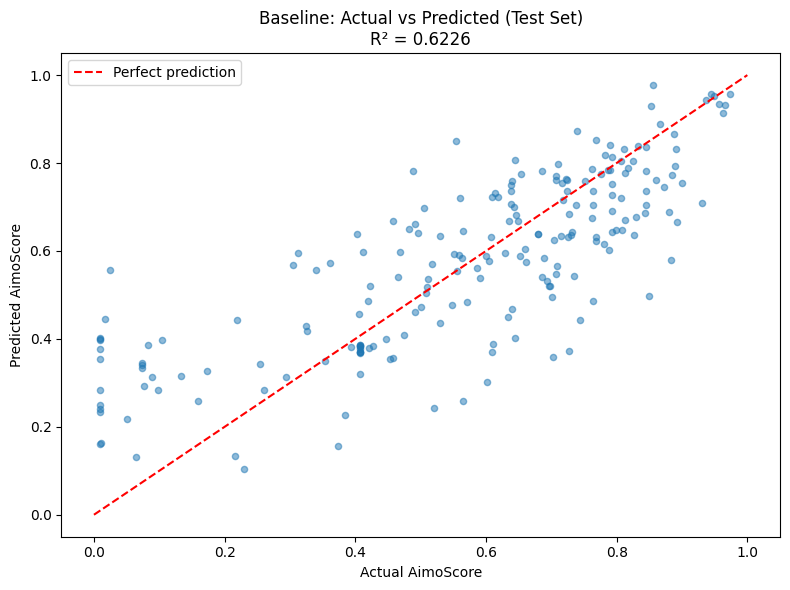


Significant features (p < 0.05): 21/41
Removed features: ['No_2_Angle_Deviation', 'No_5_Angle_Deviation', 'No_6_Angle_Deviation', 'No_7_Angle_Deviation', 'No_10_Angle_Deviation', 'No_13_Angle_Deviation', 'No_1_NASM_Deviation', 'No_2_NASM_Deviation', 'No_4_NASM_Deviation', 'No_5_NASM_Deviation', 'No_7_NASM_Deviation', 'No_11_NASM_Deviation', 'No_14_NASM_Deviation', 'No_16_NASM_Deviation', 'No_18_NASM_Deviation', 'No_20_NASM_Deviation', 'No_22_NASM_Deviation', 'No_24_NASM_Deviation', 'No_1_Time_Deviation', 'No_2_Time_Deviation']
Feature Selection: R²=0.6150, RMSE=0.1601, MAE=0.1227

Top 2 correlated features:
  EstimatedScore: r = 0.5633
  No_12_NASM_Deviation: r = 0.4967
Combined Features: R²=0.6210, RMSE=0.1588, MAE=0.1216

Outliers identified: 96 (5.1%) at |r|>2.0
Outlier Removal: R²=0.6272, RMSE=0.1575, MAE=0.1188
Weighted Least Squares: R²=0.6257, RMSE=0.1578, MAE=0.1199
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001028 seconds.
You can 

In [ ]:
def logit(y, eps=1e-6):
    y = np.clip(y, eps, 1 - eps)
    return np.log(y / (1 - y))

def inv_logit(z):
    return 1 / (1 + np.exp(-z))

# ============================================================
# PART 1 — REGRESSION (AimoScore)
# Based on: baseline_model notebook
# Metrics: R², RMSE, MAE (same as old)
# ============================================================

print("\n" + "="*80)
print("PART 1 — REGRESSION (AimoScore)")
print("="*80)

# -----------------------
# 1. Load Data (same path as old baseline_model)
# -----------------------
df_reg = pd.read_excel('../../data/raw/AimoScore_WeakLink_big_scores.xls')
print(f"Dataset: {df_reg.shape[0]} samples, {df_reg.shape[1]} columns")

# Keep old structure, but fix a common issue:
# - Drop ID (string) from features to avoid numeric coercion -> NaN for every row.
USE_ESTIMATED_SCORE = True  # try both True/False and compare test metrics
drop_cols = ['AimoScore', 'ID'] + ([] if USE_ESTIMATED_SCORE else ['EstimatedScore'])
X = df_reg.drop(columns=drop_cols, errors='ignore')
y = df_reg['AimoScore'].astype(float)

# Force numeric, keep NaNs for imputer
X = X.apply(pd.to_numeric, errors='coerce')

print(f"Features: {X.shape[1]}")
print(f"Target range: {y.min():.2f} - {y.max():.2f}")
print(f"Missing values in X: {int(X.isna().sum().sum())}")

# -----------------------
# 2. Train/Test Split (same as old)
# -----------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=RANDOM_SEED
)
print(f"Training: {X_train.shape[0]} samples")
print(f"Test:     {X_test.shape[0]} samples")

# Store results for comparison
reg_results = {}

def eval_regression_model(name, model, X_train, X_test, y_train, y_test):
    """Fit and compute same metrics as old notebook: R², RMSE, MAE."""
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    out = {
        'model': model,
        'train_r2': r2_score(y_train, y_train_pred),
        'train_rmse': float(np.sqrt(mean_squared_error(y_train, y_train_pred))),
        'train_mae': float(mean_absolute_error(y_train, y_train_pred)),
        'test_r2': r2_score(y_test, y_test_pred),
        'test_rmse': float(np.sqrt(mean_squared_error(y_test, y_test_pred))),
        'test_mae': float(mean_absolute_error(y_test, y_test_pred)),
    }
    reg_results[name] = out
    return out

# -----------------------
# 3. Baseline (same idea as old, but safer preprocessing)
# Improvement: imputation so the model doesn’t break if NaNs exist
# -----------------------
baseline_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
m = eval_regression_model("Baseline (LinearRegression + imputer)", baseline_lr, X_train, X_test, y_train, y_test)
print(f"Baseline: R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")

# Plot: Actual vs Predicted (baseline)
baseline_pred_test = reg_results["Baseline (LinearRegression + imputer)"]["model"].predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, baseline_pred_test, alpha=0.5, s=20)
plt.plot([0, 1], [0, 1], 'r--', label='Perfect prediction')
plt.xlabel('Actual AimoScore')
plt.ylabel('Predicted AimoScore')
plt.title(f"Baseline: Actual vs Predicted (Test Set)\nR² = {m['test_r2']:.4f}")
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------
# 4. Feature selection (p-value based) — same as old concept
# Improvement: do selection on imputed data (statsmodels can’t handle NaNs)
# -----------------------
X_train_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_train_const = sm.add_constant(X_train_imp)
ols_model = sm.OLS(y_train, X_train_const).fit()
pvalues = ols_model.pvalues[1:]  # skip const

significant_features = pvalues[pvalues < 0.05].index.tolist()
removed_features = pvalues[pvalues >= 0.05].index.tolist()

print(f"\nSignificant features (p < 0.05): {len(significant_features)}/{len(pvalues)}")
print(f"Removed features: {removed_features}")

# Train model on selected features (still with imputer just in case)
X_train_sig = X_train[significant_features]
X_test_sig = X_test[significant_features]
fs_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
m = eval_regression_model("Feature Selection (p<0.05) + LR", fs_lr, X_train_sig, X_test_sig, y_train, y_test)
print(f"Feature Selection: R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")

# -----------------------
# 5. Combined Features (Interaction Terms)
# Old notebook added ONE interaction between top-2 correlated features.
# Improvement: still keep that exact approach, but compute correlation on imputed data.
# -----------------------
corr = X_train_imp.corrwith(y_train).abs().sort_values(ascending=False)
top_two = corr.head(2).index.tolist()
print("\nTop 2 correlated features:")
print(f"  {top_two[0]}: r = {corr[top_two[0]]:.4f}")
print(f"  {top_two[1]}: r = {corr[top_two[1]]:.4f}")

interaction_name = f"{top_two[0]}_x_{top_two[1]}"

X_train_int = X_train.copy()
X_test_int = X_test.copy()
X_train_int[interaction_name] = X_train[top_two[0]] * X_train[top_two[1]]
X_test_int[interaction_name] = X_test[top_two[0]] * X_test[top_two[1]]

int_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
m = eval_regression_model("Combined Features (1 interaction) + LR", int_lr, X_train_int, X_test_int, y_train, y_test)
print(f"Combined Features: R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")

# -----------------------
# 6. Outlier Removal (Studentized Residuals)
# Old notebook removed |studentized residual| > 2 on training set.
# Improvement: compute on imputed X to avoid NaN issues.
# -----------------------
threshold = 2.0
X_train_const = sm.add_constant(X_train_imp)
ols_model = sm.OLS(y_train, X_train_const).fit()
influence = ols_model.get_influence()
studentized = influence.resid_studentized_external

outlier_mask = np.abs(studentized) > threshold
n_outliers = int(outlier_mask.sum())
print(f"\nOutliers identified: {n_outliers} ({100*n_outliers/len(y_train):.1f}%) at |r|>{threshold}")

X_train_clean = X_train.loc[~outlier_mask].copy()
y_train_clean = y_train.loc[~outlier_mask].copy()

out_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
m = eval_regression_model("Outlier Removal (studentized) + LR", out_lr, X_train_clean, X_test, y_train_clean, y_test)
print(f"Outlier Removal: R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")

# -----------------------
# 7. Weighted Least Squares (WLS)
# Old notebook: weights = 1/(residual^2 + eps)
# Improvement: cap extreme weights to reduce instability.
# -----------------------
initial = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
initial.fit(X_train, y_train)
y_pred_init = initial.predict(X_train)
residuals = (y_train - y_pred_init)

epsilon = 1e-6
weights = 1.0 / (residuals**2 + epsilon)

# Improvement: cap weights at 95th percentile (reduces domination by a few points)
cap = np.quantile(weights, 0.95)
weights = np.minimum(weights, cap)

# normalize to sum to n
weights = weights / weights.sum() * len(weights)

wls = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
wls.fit(X_train, y_train, model__sample_weight=weights)

# manual eval (because evaluate() fits without weights)
y_train_pred = wls.predict(X_train)
y_test_pred = wls.predict(X_test)
reg_results["Weighted Least Squares (capped) + LR"] = {
    "model": wls,
    "train_r2": r2_score(y_train, y_train_pred),
    "train_rmse": float(np.sqrt(mean_squared_error(y_train, y_train_pred))),
    "train_mae": float(mean_absolute_error(y_train, y_train_pred)),
    "test_r2": r2_score(y_test, y_test_pred),
    "test_rmse": float(np.sqrt(mean_squared_error(y_test, y_test_pred))),
    "test_mae": float(mean_absolute_error(y_test, y_test_pred)),
}
m = reg_results["Weighted Least Squares (capped) + LR"]
print(f"Weighted Least Squares: R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")

# -----------------------
# 8. Improvements: add stronger regressors (still same metrics)
# These usually beat plain linear regression if relationships are nonlinear.
# -----------------------
# Ridge + scaling
# --- Strong boosted regressors with target logit transform ---
# This keeps your reported metrics identical (R²/RMSE/MAE on original scale),
# but trains on a transformed target for better fit.

lgbm_base = LGBMRegressor(
    random_state=RANDOM_SEED,
    objective="regression",
    n_estimators=5000,          # allow early stopping
    learning_rate=0.02,
    num_leaves=127,
    max_depth=-1,
    min_child_samples=10,       # less restrictive than default
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.0,
    reg_lambda=1.0,
    n_jobs=-1
)

xgb_base = XGBRegressor(
    random_state=RANDOM_SEED,
    n_estimators=8000,          # allow early stopping
    learning_rate=0.02,
    max_depth=6,
    min_child_weight=1,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=-1,
    eval_metric="rmse",
)

# Train/valid split for early stopping (inside training only)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=RANDOM_SEED)

# LightGBM with early stopping
lgbm_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", TransformedTargetRegressor(
        regressor=lgbm_base,
        func=logit,
        inverse_func=inv_logit
    ))
])

# XGBoost with early stopping (needs fit params on inner regressor)
xgb_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", TransformedTargetRegressor(
        regressor=xgb_base,
        func=logit,
        inverse_func=inv_logit
    ))
])

# Fit LGBM using early stopping via regressor__fit params (Pipeline -> step__param)
m = eval_regression_model(
    "LightGBMRegressor (logit target, early stop)",
    lgbm_reg,
    X_tr, X_test, y_tr, y_test
)
# Refit with early stopping properly:
imp = SimpleImputer(strategy="median")
X_tr_imp = imp.fit_transform(X_tr)
X_val_imp = imp.transform(X_val)

lgbm_reg.fit(
    X_tr, y_tr,
    model__eval_set=[(X_val_imp, logit(y_val))],
    model__eval_metric="rmse",
    model__callbacks=[],
)


# Evaluate on test
y_test_pred = lgbm_reg.predict(X_test)
reg_results["LightGBMRegressor (logit target, early stop)"] = {
    "model": lgbm_reg,
    "train_r2": r2_score(y_tr, lgbm_reg.predict(X_tr)),
    "train_rmse": float(np.sqrt(mean_squared_error(y_tr, lgbm_reg.predict(X_tr)))),
    "train_mae": float(mean_absolute_error(y_tr, lgbm_reg.predict(X_tr))),
    "test_r2": r2_score(y_test, y_test_pred),
    "test_rmse": float(np.sqrt(mean_squared_error(y_test, y_test_pred))),
    "test_mae": float(mean_absolute_error(y_test, y_test_pred)),
}
m = reg_results["LightGBMRegressor (logit target, early stop)"]
print(f"LightGBM (logit): R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")

# Fit XGB without early stopping
# (Need transformed y for eval_set; TransformedTargetRegressor transforms internally for training,
# but eval_set must be in transformed space.)
m = eval_regression_model(
    "XGBRegressor (logit target, early stop)",
    xgb_reg,
    X_tr, X_test, y_tr, y_test
)
print(f"XGB (logit): R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")


# -----------------------
# 9. Model Comparison (same table idea as old)
# Old picked champion by best test R².
# We keep that rule for compatibility with old structure.
# -----------------------
print("\n" + "=" * 80)
print(f'{"Model":<38s} {"Test R²":<10s} {"Test RMSE":<12s} {"Test MAE":<12s}')
print("-" * 80)
for name, m in reg_results.items():
    print(f'{name:<38s} {m["test_r2"]:<10.4f} {m["test_rmse"]:<12.4f} {m["test_mae"]:<12.4f}')
print("=" * 80)

champion_name = max(reg_results.keys(), key=lambda k: reg_results[k]["test_r2"])
champion = reg_results[champion_name]
print(f"\nRegression Champion: {champion_name}")
print(f"  R²   = {champion['test_r2']:.4f}")
print(f"  RMSE = {champion['test_rmse']:.4f}")
print(f"  MAE  = {champion['test_mae']:.4f}")

# -----------------------
# 10. Optional small tuning for champion if boosted (improves model)
# Keeps same save structure from old notebook.
# -----------------------
tuned_champion_model = champion["model"]

if ("LightGBM" in champion_name) or ("XGB" in champion_name):
    print("\nTuning champion with small RandomizedSearchCV (5-fold CV) ...")
    cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

    if "LightGBM" in champion_name:
        param_dist = {
            "model__regressor__num_leaves": [31, 63, 127, 255],
            "model__regressor__min_child_samples": [5, 10, 20, 40],
            "model__regressor__subsample": [0.7, 0.85, 1.0],
            "model__regressor__colsample_bytree": [0.7, 0.85, 1.0],
            "model__regressor__learning_rate": [0.01, 0.02, 0.03, 0.05],
            "model__regressor__n_estimators": [1500, 3000, 5000],
            "model__regressor__reg_lambda": [0.0, 0.5, 1.0, 2.0],
        }
    else:
        param_dist = {
            "model__regressor__max_depth": [3, 4, 5, 6, 8],
            "model__regressor__subsample": [0.7, 0.85, 1.0],
            "model__regressor__colsample_bytree": [0.7, 0.85, 1.0],
            "model__regressor__learning_rate": [0.01, 0.02, 0.03, 0.05],
            "model__regressor__n_estimators": [1500, 3000, 6000],
            "model__regressor__reg_lambda": [0.0, 0.5, 1.0, 2.0],
        }


    # score = negative RMSE (we still REPORT R²/RMSE/MAE like old; tuning uses RMSE)
    def neg_rmse(est, Xv, yv):
        pred = est.predict(Xv)
        return -np.sqrt(mean_squared_error(yv, pred))

    search = RandomizedSearchCV(
        tuned_champion_model,
        param_distributions=param_dist,
        n_iter=20,
        scoring=neg_rmse,
        cv=cv_reg,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_train, y_train)
    tuned_champion_model = search.best_estimator_
    print("Best CV neg RMSE:", float(search.best_score_))

    # re-evaluate tuned model on test (same metrics)
    tuned_name = f"{champion_name} (tuned)"
    m = eval_regression_model(tuned_name, tuned_champion_model, X_train, X_test, y_train, y_test)
    print(f"Tuned test: R²={m['test_r2']:.4f}, RMSE={m['test_rmse']:.4f}, MAE={m['test_mae']:.4f}")

    # update champion selection if tuning improved R²
    new_champ = max(reg_results.keys(), key=lambda k: reg_results[k]["test_r2"])
    champion_name = new_champ
    champion = reg_results[champion_name]
    print("\nUpdated Regression Champion:", champion_name)

# -----------------------
# 11. Save Champion Model (same structure as old baseline_model)
# -----------------------
os.makedirs('../../../trained_models/A4', exist_ok=True)

champion_model = reg_results[champion_name]["model"]
joblib.dump(champion_model, '../../../trained_models/A4/champion_model.pkl')

# Save feature names + metadata like old
if champion_name == "Feature Selection (p<0.05) + LR":
    feature_names = significant_features
elif champion_name == "Combined Features (1 interaction) + LR":
    feature_names = list(X_train_int.columns)
else:
    feature_names = list(X_train.columns)

metadata = {
    'name': champion_name,
    'feature_names': feature_names,
    'test_r2': reg_results[champion_name]['test_r2'],
    'test_rmse': reg_results[champion_name]['test_rmse'],
    'test_mae': reg_results[champion_name]['test_mae'],
}

joblib.dump(feature_names, '../../../trained_models/A4/champion_feature_names.pkl')
joblib.dump(metadata, '../../../trained_models/A4/champion_metrics.pkl')

print("\nSaved Regression Champion:")
print(f"  - ../trained_models/champion_model.pkl")
print(f"  - ../trained_models/champion_feature_names.pkl ({len(feature_names)} features)")
print(f"  - ../trained_models/champion_metrics.pkl")


PART 2 — CLASSIFICATION (WeakestLink)
scores: (2096, 17) big: (2094, 43)
Tie rows: 372
Label null rows: 0
After merge: (1724, 45)
Unique classes: 10
After dropping NaNs: (1724, 38) (1724,)
Final dataset: (1724, 38)
Smallest class count: 46
Using cv_splits = 5


,dataset_tag,cv_folds,removed_weakest_links,drop_ties,model,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_weighted_mean
0,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,lightgbm,0.649004,0.571860,0.538198,0.534883,0.639470
1,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,xgboost,0.627252,0.545927,0.505507,0.505741,0.614008
2,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,logreg_C1_balanced,0.535162,0.471180,0.543294,0.481355,0.547555
3,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,logreg_C0.3_balanced,0.530812,0.464991,0.545721,0.476393,0.541811
4,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,lda,0.576480,0.483477,0.485691,0.475825,0.571967
5,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,lda_lsqr_shrinkage_auto,0.576474,0.481721,0.478185,0.468491,0.569195
6,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,gaussian_nb,0.487304,0.431060,0.487230,0.435244,0.495641
7,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,knn_k5,0.552545,0.455609,0.425849,0.428697,0.543795
8,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,knn_k15,0.569950,0.492498,0.415687,0.422004,0.548074
9,combined_notebook,5,"LeftHeelRises, LeftKneeMovesInward, RightAsymm...",True,dummy_most_frequent,0.263236,0.026324,0.100000,0.041676,0.109711



Classification Champion (by CV macro-F1): lightgbm

Tuning classification champion (small RandomizedSearchCV) ...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV macro-F1: 0.5124599709618065


C:\Users\kimwo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== TEST METRICS (same metrics as old notebook) ===
{'accuracy': 0.663768115942029, 'precision_macro': 0.6424397248317093, 'recall_macro': 0.580563211642159, 'f1_macro': 0.579334395256942, 'f1_weighted': 0.6574956405441509}

=== CLASSIFICATION REPORT ===
                             precision    recall  f1-score   support

       ExcessiveForwardLean       0.56      0.75      0.64        20
                ForwardHead       0.50      0.63      0.56        19
         LeftArmFallForward       0.57      0.59      0.58        66
LeftAsymmetricalWeightShift       0.62      0.71      0.67        14
       LeftKneeMovesOutward       0.67      0.60      0.63        10
      LeftShoulderElevation       1.00      0.20      0.33        10
        RightArmFallForward       0.66      0.68      0.67        91
       RightKneeMovesInward       0.25      0.11      0.15         9
      RightKneeMovesOutward       0.96      0.95      0.95        56
     RightShoulderElevation       0.63      0.58     

,ExcessiveForwardLean,ForwardHead,LeftArmFallForward,LeftAsymmetricalWeightShift,LeftKneeMovesOutward,LeftShoulderElevation,RightArmFallForward,RightKneeMovesInward,RightKneeMovesOutward,RightShoulderElevation
ExcessiveForwardLean,15,1,1,0,0,0,3,0,0,0
ForwardHead,2,12,2,0,0,0,2,0,0,1
LeftArmFallForward,2,1,39,1,1,0,15,0,0,7
LeftAsymmetricalWeightShift,0,1,0,10,0,0,1,0,0,2
LeftKneeMovesOutward,1,0,1,1,6,0,1,0,0,0
LeftShoulderElevation,2,0,0,1,1,2,2,0,0,2
RightArmFallForward,3,6,17,1,0,0,62,0,0,2
RightKneeMovesInward,2,0,2,0,0,0,1,1,1,2
RightKneeMovesOutward,0,0,2,0,0,0,0,0,53,1
RightShoulderElevation,0,3,4,2,1,0,7,3,1,29


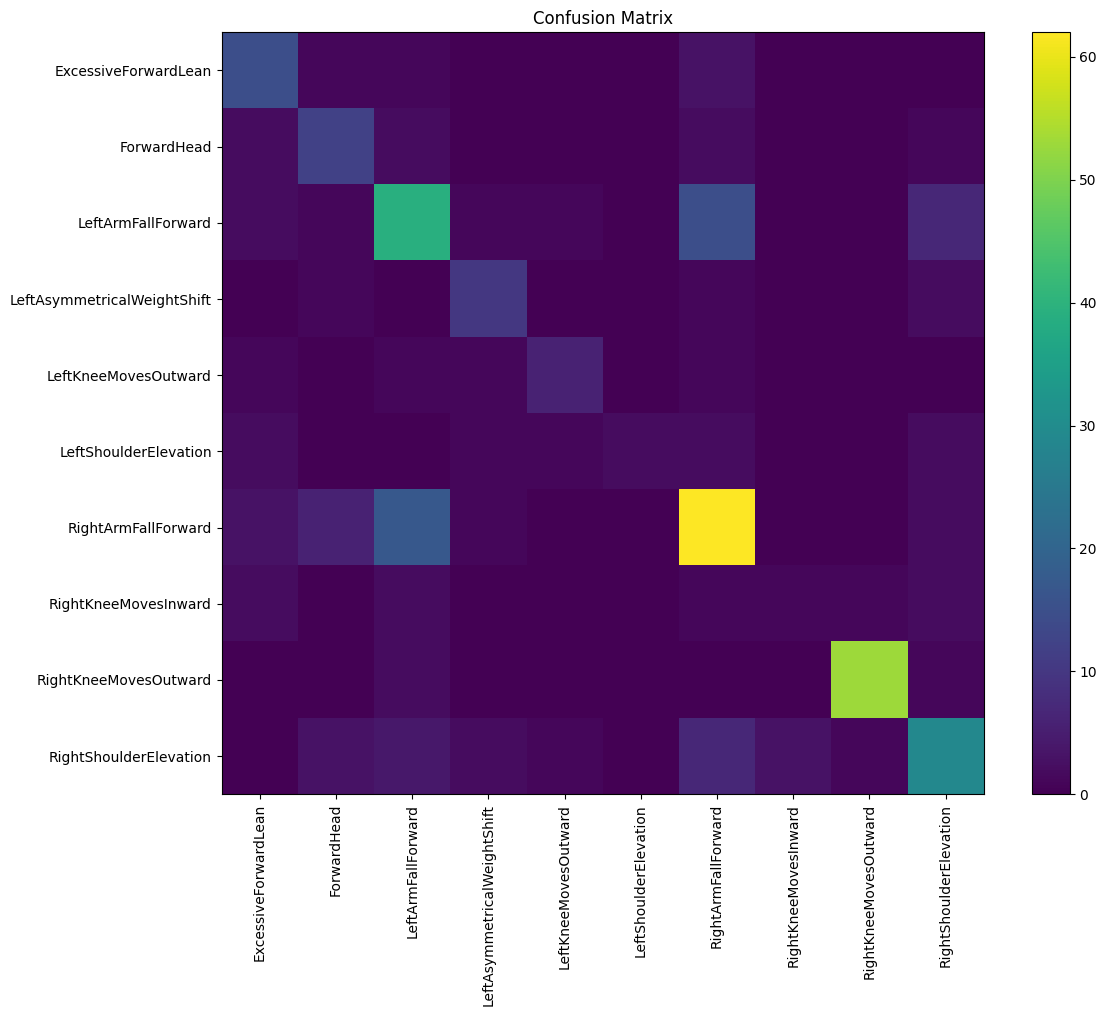


Saved classification model + meta to: ..\..\..\trained_models\A4\weakest_link_model

=== Class coverage: full dataset vs train vs test ===


,full_dataset,training_set,test_set,present_in_train,present_in_test
WeakestLink,,,,,
RightKneeMovesInward,46,37,9,True,True
LeftKneeMovesOutward,49,39,10,True,True
LeftShoulderElevation,51,41,10,True,True
LeftAsymmetricalWeightShift,71,57,14,True,True
ForwardHead,96,77,19,True,True
ExcessiveForwardLean,99,79,20,True,True
RightShoulderElevation,252,202,50,True,True
RightKneeMovesOutward,278,222,56,True,True
LeftArmFallForward,328,262,66,True,True


In [25]:
def supports_sample_weight(model) -> bool:
    """Return True if the final estimator inside the pipeline supports sample_weight."""
    try:
        est = model.named_steps["clf"] if isinstance(model, Pipeline) else model
    except Exception:
        est = model
    return "sample_weight" in est.fit.__code__.co_varnames

# ============================================================
# PART 2 — CLASSIFICATION (WeakestLink)
# Based on: old weakest_link_classification notebook
# Metrics: accuracy, precision_macro, recall_macro, f1_macro, f1_weighted (same as old)
# ============================================================

print("\n" + "="*80)
print("PART 2 — CLASSIFICATION (WeakestLink)")
print("="*80)

# -----------------------
# Load input datasets (same as old weakest_link notebook)
# -----------------------
DATA_DIR = Path("../..") / "data/processed"
scores_path = DATA_DIR / "20190108_scores_and_weak_links.csv"
big_path = DATA_DIR / "AimoScore_WeakLink_big_scores.csv"

scores = pd.read_csv(scores_path)
big = pd.read_csv(big_path)

print("scores:", scores.shape, "big:", big.shape)

# -----------------------
# Create WeakestLink labels (rule-based) (same as old)
# Improvements:
# - Optional DROP_TIES training switch (off by default in old main run)
# - Keep DROP_WEAK_LINKS as in old
# -----------------------
NON_INDICATORS = {"ID", "Date", "SCORE"}
indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]

DROP_WEAK_LINKS = {
    "LeftHeelRises",
    "RightHeelRises",
    "LeftKneeMovesInward",
    "RightAsymmetricalWeightShift"
}
indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]

scores[indicator_cols] = scores[indicator_cols].apply(pd.to_numeric, errors="coerce")

row_max = scores[indicator_cols].max(axis=1)
ties = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)

scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)
scores["HasTie"] = ties

print("Tie rows:", int(scores["HasTie"].sum()))
print("Label null rows:", int(scores["WeakestLink"].isna().sum()))

# Toggle (improvement option): train on no-tie data for clearer supervision
DROP_TIES = True
labels = scores[["ID", "WeakestLink", "HasTie"]].dropna()
if DROP_TIES:
    labels = labels.loc[~labels["HasTie"]].copy()

# -----------------------
# Merge labels with feature dataset (same as old)
# -----------------------
data = big.merge(labels, on="ID", how="inner")
print("After merge:", data.shape)
print("Unique classes:", data["WeakestLink"].nunique())

# -----------------------
# Feature selection & cleaning (same 38 features as old)
# -----------------------
angle_cols = [f"No_{i}_Angle_Deviation" for i in range(1, 14)]
nasm_cols = [f"No_{i}_NASM_Deviation" for i in range(1, 26)]
feature_cols = angle_cols + nasm_cols

Xc = data[feature_cols].apply(pd.to_numeric, errors="coerce")
yc = data["WeakestLink"].astype(str)

# Improvement: imputer in pipelines means we don't need to drop all NaNs,
# but we keep the old behavior here for comparability.
#mask = Xc.notna().all(axis=1)
#Xc, yc = Xc.loc[mask], yc.loc[mask]

print("After dropping NaNs:", Xc.shape, yc.shape)

# Handle singleton classes (same as old)
counts = yc.value_counts()
singletons = counts[counts < 2].index
X2 = Xc.loc[~yc.isin(singletons)].copy()
y2 = yc.loc[~yc.isin(singletons)].copy()

print("Final dataset:", X2.shape)
print("Smallest class count:", int(y2.value_counts().min()))

# -----------------------
# Train/test split & CV setup (same logic as old)
# -----------------------
X_train, X_test, y_train, y_test = train_test_split(
    X2, y2,
    test_size=0.1,
    random_state=RANDOM_SEED,
    stratify=y2
)

# Balanced sample weights -> improves minority classes and macro-F1
sample_weight_train = compute_sample_weight(class_weight="balanced", y=y_train)


min_class = int(y_train.value_counts().min())
cv_splits = max(2, min(5, min_class))

cv = StratifiedKFold(
    n_splits=cv_splits,
    shuffle=True,
    random_state=RANDOM_SEED
)

print("Using cv_splits =", cv_splits)

# -----------------------
# Label encoding for XGBoost (same as old, but used more robustly)
# -----------------------
label_encoder = LabelEncoder()
y2_encoded = label_encoder.fit_transform(y2)
class_names = list(label_encoder.classes_)

X_train_enc, X_test_enc, y_train_enc, y_test_enc = train_test_split(
    X2, y2_encoded,
    test_size=0.1,
    random_state=RANDOM_SEED,
    stratify=y2_encoded
)

sample_weight_train_enc = compute_sample_weight(class_weight="balanced", y=y_train_enc)

# -----------------------
# Model definitions (same set as old, minus CatBoost if you prefer)
# Improvements:
# - add SimpleImputer so you can remove the hard drop-na if you want later
# - use class_weight balanced where applicable
# - update boosting defaults to be a bit stronger, still “reasonable”
# -----------------------
models = {
    "dummy_most_frequent": DummyClassifier(strategy="most_frequent"),

    "logreg_C1_balanced": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            class_weight="balanced",
            C=1.0
        ))
    ]),
    "logreg_C0.3_balanced": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=5000,
            class_weight="balanced",
            C=0.3
        ))
    ]),

    "gaussian_nb": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", GaussianNB())
    ]),

    "lda": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LinearDiscriminantAnalysis())
    ]),

    "lda_lsqr_shrinkage_auto": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    ]),

    "knn_k5": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
    "knn_k15": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15))
    ]),
    
    "xgboost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", XGBClassifier(
            n_estimators=5000,
            learning_rate=0.03,
            max_depth=6,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_alpha=0.0,
            reg_lambda=1.0,
            objective="multi:softprob",
            eval_metric="mlogloss",
            num_class=len(class_names),
            random_state=RANDOM_SEED,
            tree_method="hist",
            n_jobs=-1
        ))
    ]),

    "lightgbm": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(class_names),
            n_estimators=5000,
            learning_rate=0.03,
            num_leaves=127,
            min_child_samples=10,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_alpha=0.0,
            reg_lambda=1.0,
            random_state=RANDOM_SEED,
            n_jobs=-1,
            verbosity=-1
        ))
    ]),

}

# -----------------------
# Cross-validation comparison (same metrics as old)
# -----------------------
DATASET_TAG = "combined_notebook"

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

removed_links_str = ", ".join(sorted(list(DROP_WEAK_LINKS))) if DROP_WEAK_LINKS else "None"

rows = []
for name, model in models.items():
    # Old rule: encoded labels only for xgboost
    if name == "xgboost":
        Xtr, ytr = X_train_enc, y_train_enc
        sw = sample_weight_train_enc
    else:
        Xtr, ytr = X_train, y_train
        sw = sample_weight_train

    # Only pass sample_weight if the model supports it
    if name == "dummy_most_frequent":
        params = {}
    elif supports_sample_weight(model):
        params = {"clf__sample_weight": sw}
    else:
        params = {}

    out = cross_validate(
        model,
        Xtr, ytr,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        params=params
    )

    row = {
        "dataset_tag": DATASET_TAG,
        "cv_folds": cv_splits,
        "removed_weakest_links": removed_links_str,
        "drop_ties": bool(DROP_TIES),
        "model": name,
    }
    for m in scoring:
        row[f"{m}_mean"] = float(np.mean(out[f"test_{m}"]))
    rows.append(row)


results_df = (
    pd.DataFrame(rows)
    .sort_values("f1_macro_mean", ascending=False)  # old notebook sorted by macro-F1
    .reset_index(drop=True)
)

display(results_df)

# -----------------------
# Pick champion (same as old: best by CV macro-F1)
# -----------------------
best_name = results_df.iloc[0]["model"]
best_model = models[best_name]
print("\nClassification Champion (by CV macro-F1):", best_name)

# -----------------------
# Optional small tuning for best boosted model (improvement)
# Uses SAME metrics for reporting; tuning uses macro-F1 on CV.
# -----------------------
tuned_model = best_model
if best_name in {"xgboost", "lightgbm"}:
    print("\nTuning classification champion (small RandomizedSearchCV) ...")
    if best_name == "xgboost":
        param_dist = {
            "clf__max_depth": [3, 4, 5, 6, 8],
            "clf__subsample": [0.7, 0.85, 1.0],
            "clf__colsample_bytree": [0.7, 0.85, 1.0],
            "clf__learning_rate": [0.02, 0.05, 0.1],
            "clf__n_estimators": [400, 800, 1200],
        }
        # IMPORTANT: keep encoded y for XGB
        Xtr, ytr = X_train_enc, y_train_enc
    else:
        param_dist = {
            "clf__num_leaves": [31, 63, 127],
            "clf__min_child_samples": [10, 20, 40, 80],
            "clf__subsample": [0.7, 0.85, 1.0],
            "clf__colsample_bytree": [0.7, 0.85, 1.0],
            "clf__learning_rate": [0.02, 0.05, 0.1],
            "clf__n_estimators": [400, 800, 1200],
        }
        Xtr, ytr = X_train, y_train

    search = RandomizedSearchCV(
        best_model,
        param_distributions=param_dist,
        n_iter=20,
        scoring="f1_macro",
        cv=cv,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=1
    )
    search.fit(Xtr, ytr)
    tuned_model = search.best_estimator_
    print("Best CV macro-F1:", float(search.best_score_))
    best_name = f"{best_name} (tuned)"

# -----------------------
# Train final champion model + evaluate on test set (same as old)
# -----------------------
is_xgb = best_name.startswith("xgboost")
is_lgbm = best_name.startswith("lightgbm")

if is_xgb:
    tuned_model.fit(X_train_enc, y_train_enc, clf__sample_weight=sample_weight_train_enc)
    pred_enc = tuned_model.predict(X_test_enc)
    y_pred = label_encoder.inverse_transform(pred_enc.astype(int))
    y_true = label_encoder.inverse_transform(y_test_enc.astype(int))

elif is_lgbm:
    # LGBM supports sample_weight, but your xgboost version issues suggest avoiding early stopping logic here too
    tuned_model.fit(X_train, y_train, clf__sample_weight=sample_weight_train)
    y_pred = tuned_model.predict(X_test)
    y_true = y_test

else:
    # No early stopping, and only sample_weight if supported
    if supports_sample_weight(tuned_model):
        tuned_model.fit(X_train, y_train, clf__sample_weight=sample_weight_train)
    else:
        tuned_model.fit(X_train, y_train)

    y_pred = tuned_model.predict(X_test)
    y_true = y_test



print("\n=== TEST METRICS (same metrics as old notebook) ===")
test_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
}
print(test_metrics)

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, zero_division=0))

# -----------------------
# Confusion matrix (same as old)
# -----------------------
labels_sorted = sorted(pd.unique(y_true))
cm = confusion_matrix(y_true, y_pred, labels=labels_sorted)
cm_df = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)
display(cm_df)

plt.figure(figsize=(12, 10))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks(range(len(labels_sorted)), labels_sorted, rotation=90)
plt.yticks(range(len(labels_sorted)), labels_sorted)
plt.tight_layout()
plt.show()

# -----------------------
# Save final champion model (same structure as old)
# -----------------------
OUT_MODEL_DIR = Path("../../..") / "trained_models/A4/weakest_link_model"
OUT_MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(tuned_model, OUT_MODEL_DIR / "champion_model.joblib")

# Save label encoder only if xgboost is used (same rule as old)
uses_label_encoder = ("xgboost" in best_name)
if uses_label_encoder:
    joblib.dump(label_encoder, OUT_MODEL_DIR / "label_encoder.joblib")

meta = {
    "feature_cols": feature_cols,
    "model_name": best_name,
    "classes": class_names if uses_label_encoder else sorted(y2.unique().tolist()),
    "cv_splits": cv_splits,
    "dropped_weakest_links": sorted(list(DROP_WEAK_LINKS)) if DROP_WEAK_LINKS else [],
    "drop_ties": bool(DROP_TIES),
    "uses_label_encoder": uses_label_encoder,
}

(OUT_MODEL_DIR / "champion_meta.json").write_text(json.dumps(meta, indent=2))
print("\nSaved classification model + meta to:", OUT_MODEL_DIR)

# -----------------------
# Quick sanity: class coverage
# -----------------------
print("\n=== Class coverage: full dataset vs train vs test ===")
coverage_df = pd.DataFrame({
    "full_dataset": y2.value_counts(),
    "training_set": pd.Series(y_train).value_counts(),
    "test_set": pd.Series(y_test).value_counts(),
}).fillna(0).astype(int)

coverage_df["present_in_train"] = coverage_df["training_set"] > 0
coverage_df["present_in_test"] = coverage_df["test_set"] > 0

display(coverage_df.sort_values("full_dataset"))
